# AI-Driven Smart-City Traffic and Energy Optimization System
**Name:** Margaret Gonzalez
**Course:** Advanced Artificial Intelligence (COS570), Full Sail University  
**Assignment 1:** Smart-city simulation controlling traffic lights and energy use across multiple intersections and zones.

This notebook runs the complete, reproducible pipeline:

1. **City environment setup** - 3 x 3 grid of signalized intersections, 300 m road links, and four energy zones (SimPy discrete-event simulation).
2. **Traffic light automation** - fixed-time baseline, rule-based actuated control, and a Q-learning reinforcement-learning agent.
3. **Energy grid management** - building loads by time of day, rooftop solar, batteries, street lighting, and inter-zone sharing.
4. **AI optimization** - Q-learning minimizes waiting time; a gradient-boosting regression model forecasts load to minimize energy wastage.
5. **Visualization** - charts, heatmaps, and an animated city view.
6. **Performance analysis and validation** - delay, throughput, energy efficiency, stress test, and automated tests.

All code lives in `smart_city_sim.py` (simulation and AI models) and `run_experiments.py` (experiments and figures). Keep this notebook in the same folder as those files.

In [1]:
import sys, os, json, subprocess, time
import numpy as np
import pandas as pd
from IPython.display import Image, Video, display, HTML
import smart_city_sim as sc
import run_experiments as rx
pd.set_option("display.precision", 2)
print("Python", sys.version.split()[0], "| SimPy", sc.simpy.__version__, "| pandas", pd.__version__, "| numpy", np.__version__)

Python 3.14.7 | SimPy 4.1.2 | pandas 3.0.6 | numpy 2.5.3


## 1. City environment setup
Energy zones, rooftop solar (PV), batteries, and the intersections each zone contains.

,Buildings,Avg kW/bldg,Profile,PV (kWp),Battery (kWh),Battery (kW),Street lights,Intersections
Residential,120,1.3,res,420,600,150,70,"[0, 1, 3]"
Commercial,25,36.0,com,380,900,260,90,"[2, 4, 5]"
Industrial,8,55.0,ind,950,500,200,50,"[7, 8]"
Mixed-Use,30,9.0,mix,380,400,120,60,[6]


[13:51:54] saved figure outputs\figures\fig01_city_map.png


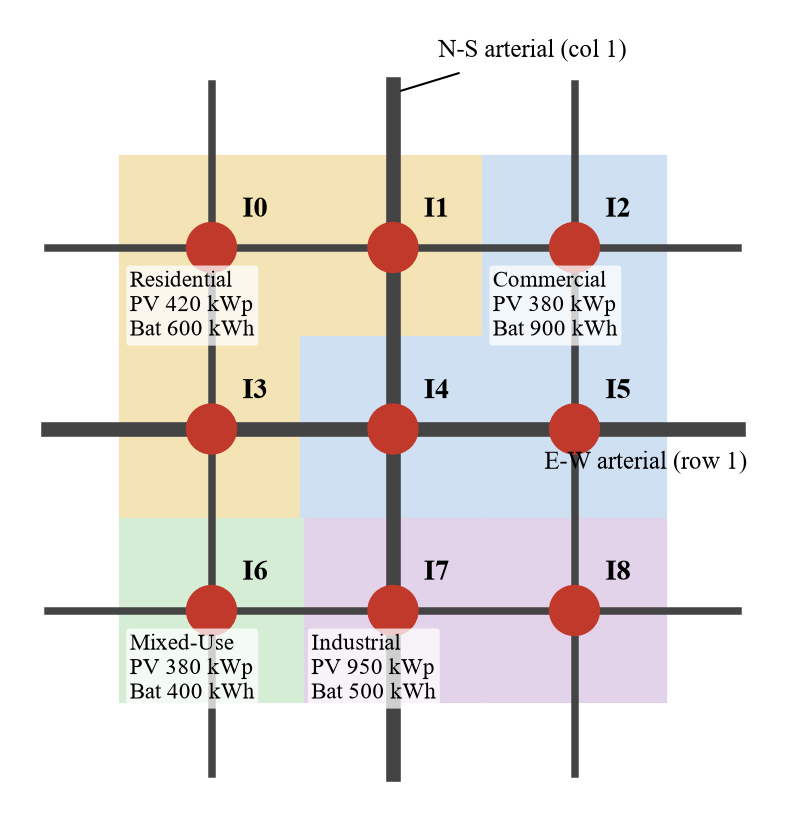

In [2]:
zones = pd.DataFrame(sc.ZONES).T[["n", "kw", "kind", "pv", "bat", "pkw", "lights", "iids"]]
zones.columns = ["Buildings", "Avg kW/bldg", "Profile", "PV (kWp)", "Battery (kWh)", "Battery (kW)", "Street lights", "Intersections"]
display(zones)
os.makedirs(rx.FIG, exist_ok=True)
rx.fig_city_map()
display(Image(os.path.join(rx.FIG, "fig01_city_map.png"), width=420))

## 2. Quick demonstration: three signal controllers during the morning peak (07:00-09:00)
The Q-learning agent here is untrained (all Q-values zero, so it falls back to a simple pressure rule). The trained agent is evaluated in Section 3.

In [3]:
rows = []
for ctrl in [sc.FixedTimeController(), sc.ActuatedController(), sc.QLearningController(alpha=0, epsilon=0)]:
    t = time.time()
    city, grid, veh, samp = sc.run_day(ctrl, seed=42, hours=2, start_hour=7, with_energy=False)
    m = sc.traffic_metrics(city, veh, hours=2)
    m["runtime_s"] = time.time() - t
    rows.append(m)
display(pd.DataFrame(rows).set_index("controller")[["vehicles_generated", "vehicles_completed", "avg_delay_s", "p95_delay_s", "throughput_vph", "conflict_violations", "runtime_s"]])

,vehicles_generated,vehicles_completed,avg_delay_s,p95_delay_s,throughput_vph,conflict_violations,runtime_s
controller,,,,,,,
Fixed-time,7608,7487,48.50,97.32,3743.5,0,0.21
Rule-based actuated,7542,7469,24.89,57.10,3734.5,0,0.18
Q-learning (RL),7588,7503,25.09,55.12,3751.5,0,0.31


## 3. Full experiment pipeline
Trains the Q-learning agent (240 episodes), trains the load forecaster, evaluates each controller on five independent 24-hour days, runs a +20% demand stress test, and saves every figure, CSV file, and the animation to `outputs/`. Runtime is about 4 to 6 minutes.

In [ ]:
rx.main(quick=False)

[13:51:55] Step 1/5: building city map
[13:51:55] saved figure outputs\figures\fig01_city_map.png
[13:51:55] Step 2/5: training Q-learning agent (240 episodes)
[13:52:01]   episode  20  eps=0.53  avg wait=19.5 s  states=166
[13:52:07]   episode  40  eps=0.46  avg wait=24.5 s  states=205
[13:52:13]   episode  60  eps=0.39  avg wait=20.4 s  states=213
[13:52:19]   episode  80  eps=0.32  avg wait=16.5 s  states=227
[13:52:26]   episode 100  eps=0.25  avg wait=34.4 s  states=237
[13:52:32]   episode 120  eps=0.17  avg wait=16.4 s  states=258
[13:52:38]   episode 140  eps=0.10  avg wait=14.6 s  states=263
[13:52:45]   episode 160  eps=0.05  avg wait=28.9 s  states=274
[13:52:52]   episode 180  eps=0.05  avg wait=10.9 s  states=289
[13:52:59]   episode 200  eps=0.05  avg wait=17.2 s  states=293


## 4. Results tables

In [ ]:
tm = pd.read_csv("outputs/data/traffic_metrics_by_seed.csv")
traffic = tm.groupby("controller")[["avg_delay_s", "p95_delay_s", "throughput_vph", "total_wait_veh_h", "signal_switches"]].agg(["mean", "std"])
display(traffic)
fixed = tm[tm.controller == "Fixed-time"].avg_delay_s.mean()
rule = tm[tm.controller == "Rule-based actuated"].avg_delay_s.mean()
rl = tm[tm.controller == "Q-learning (RL)"].avg_delay_s.mean()
print(f"Q-learning delay reduction vs fixed-time: {100*(1-rl/fixed):.1f}%   vs rule-based: {100*(1-rl/rule):.1f}%")

In [ ]:
em = pd.read_csv("outputs/data/energy_metrics_by_seed.csv").drop(columns="seed")
energy = em.groupby("policy").mean().T
energy["change_%"] = 100 * (energy["AI-optimized"] / energy["Baseline"] - 1)
display(energy)

In [ ]:
stress = pd.read_csv("outputs/data/stress_test_120pct.csv")
display(stress.groupby("controller")[["avg_delay_s", "p95_delay_s", "throughput_vph", "left_in_system"]].mean())

## 5. Visualizations

In [ ]:
for f in ["fig02_q_learning_training.png", "fig03_delay_by_hour.png", "fig04_traffic_metrics.png",
          "fig05_queue_heatmaps.png", "fig06_energy_heatmaps.png", "fig07_energy_dispatch.png",
          "fig08_load_forecast.png", "fig09_density_vs_energy.png", "fig10_energy_metrics.png"]:
    print(f)
    display(Image(os.path.join(rx.FIG, f), width=520))

### Animated city view (24 hours, 10-minute frames)

In [ ]:
display(Video("outputs/city_simulation.mp4", embed=False, width=720))
display(Image("outputs/figures/anim_frame_08h.png", width=720))

## 6. Explaining the learned Q-learning policy
For each queue-pressure level (red-direction queue minus green-direction queue), the table shows the share of visited states in which the trained agent chooses to **switch**. A sensible policy keeps the green when pressure is negative and switches as pressure grows.

In [ ]:
Q = np.load("outputs/data/q_table.npy")
labels = ["<=-6", "-5..-3", "-2..0", "1..2", "3..4", "5..7", "8..11", ">=12"]
visited = np.abs(Q).sum(axis=-1) > 0
switch = (Q[..., 1] > Q[..., 0]) & visited
policy = pd.DataFrame({"pressure (veh)": labels,
                       "visited states": [int(visited[i].sum()) for i in range(8)],
                       "share choosing SWITCH": [switch[i].sum() / max(visited[i].sum(), 1) for i in range(8)]})
display(policy)

## 7. Validation and testing

In [ ]:
res = subprocess.run([sys.executable, "-m", "pytest", "-v", "--color=no", "tests"], capture_output=True, text=True)
print(res.stdout[-3500:])
open("outputs/pytest_results.txt", "w").write(res.stdout)
subprocess.run([sys.executable, "make_evidence_images.py"])

## 8. Export the simulation trace for the Unity 3D playback
Re-runs evaluation day 1 for each controller with trace logging switched on and writes the CSV files that the Unity project reads from `Assets/StreamingAssets/SmartCityData`. The printed delays must match seed 1 in the results table, which confirms that the Unity scene replays exactly the simulated day.

In [ ]:
res = subprocess.run([sys.executable, "export_unity_data.py", "--unity-dir", "../SmartCityUnity"],
                     capture_output=True, text=True)
print(res.stdout, res.stderr)